# Lab 08: Dynamic Web Pages with Selenium

*INFO 4617/5617 · Week 8 · Chapter 8, [Dynamic Web Pages with Selenium](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-08-dynamic-pages.html)*

Today we code together. Each step below says what we're building and why, and its code cell holds only the comments that frame it: we write the code live, in class. Nothing here is turned in. After each step, a **💬 Discuss** box holds questions to talk over before the next one; click it to open it.

We'll work on the chapter's practice site, [Quotes to Scrape](https://quotes.toscrape.com), which serves the same quotes as plain HTML, as a script, through a hidden API, behind a ten-second delay, as an infinite scroll, and behind a login. First we check by hand and with `requests` whether a page needs a browser at all; then we drive Chrome from Python, headless, to find, click, type, wait, scroll, and log in; and last we do the same with a Playwright script.

**Before class:** finish [week 8's setup handout](../../handouts/week-08/README.md), so that Chrome opened from chapter 8's notebook. Open this notebook in the same environment (`webdata`, or Anaconda's own). Have your email address ready for the User-Agent. Step 11 needs Playwright's browsers, about 320 MB: if you want to run it yourself, run `python -m playwright install chromium` at home first.

On Friday, run every cell above where we stopped (**Run → Run All Above Selected Cell**).

> **Instructor key.** Every cell is filled in and was run against the live sites on 2026-10-21, headless, from the textbook at commit `d9306b7`. The quotes sandbox's answers (counts, authors, the login's 10 links) will match a rerun; xkcd's front-page comic, the random comic, Chrome's version, and every timing will not. The key ran on a Linux server as root, where Chrome won't start without `--no-sandbox` (the chapter's "Headless Mode", "On a server or in a container"), so the run set the environment variable `LAB_CHROME_FLAGS` to `--no-sandbox --disable-dev-shm-usage`, which Step 3's `make_options()` reads; on a laptop it is unset and changes nothing. Step 10 read the practice password from `QUOTES_PASSWORD`. Every cell was run.

## Step 0 — Set up (5 minutes)

Import what we'll use: `requests`, BeautifulSoup, `pandas`, `matplotlib`, and `time`, `json`, `re`, `os`, `sys`, and `Path`. Define the User-Agent that our `requests` calls send. Then repeat step 1 of the chapter's "Before the First Browser": Selenium Manager reads its settings from environment variables each time it runs, and they last only until the kernel restarts, so set them before anything starts a browser. `SE_SKIP_DRIVER_IN_PATH` makes it ignore stray drivers on your `PATH`; `SE_AVOID_STATS` stops the usage statistics it otherwise sends.

Last, `HEADLESS`, the one switch the chapter recommends: `True` runs Chrome with no window ("Headless Mode"); `False` opens a window you can watch. The key uses `True`, because it runs on a server with no screen. **On your laptop, set it to `False`**: watching the browser is how you catch a click that lands on the wrong button.

In [1]:
# Import requests, BeautifulSoup, pandas (as pd), matplotlib.pyplot (as plt), time, json, re, os, sys, and Path
# Define HEADERS with the User-Agent "WebDataScience/1.0 (your-email@colorado.edu)", with your email
# Set Selenium Manager's settings: SE_MANAGER_PATH if conda put it in the environment's bin (or Scripts) folder,
#   SE_SKIP_DRIVER_IN_PATH="true", SE_AVOID_STATS="true"; print selenium's version (4.20 or later)
# Set HEADLESS: True runs Chrome with no window; False opens one you can watch (use False on your laptop)
import json
import os
import re
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
import selenium
from bs4 import BeautifulSoup

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}

manager = Path(sys.prefix) / ("Scripts/selenium-manager.exe" if os.name == "nt" else "bin/selenium-manager")
if "SE_MANAGER_PATH" not in os.environ and manager.is_file():
    os.environ["SE_MANAGER_PATH"] = str(manager)
os.environ["SE_SKIP_DRIVER_IN_PATH"] = "true"
os.environ["SE_AVOID_STATS"] = "true"
print("selenium", selenium.__version__)
print("Selenium Manager:", os.environ.get("SE_MANAGER_PATH", "inside the selenium package"))

HEADLESS = True

selenium 4.51.0
Selenium Manager: inside the selenium package


<details>
<summary>💬 Discuss</summary>

- In week 2 we wrote a User-Agent that names us and how to reach us. Chrome sends its own. Who will the sites in today's lab think is visiting when Selenium drives it?
- Selenium Manager sends usage statistics unless `SE_AVOID_STATS` is set. What does it learn about you, and would you have known without reading the chapter?
- Why keep `HEADLESS` in one place, rather than writing `--headless=new` into each cell that starts a browser?

</details>

## Step 1 — What `requests` sees (5 minutes)

The chapter's first check is by hand: open <https://quotes.toscrape.com/js/>, right-click, and choose **View Page Source**. Ten quotes are on the screen, but there's no `<div class="quote">` in the source. Then turn JavaScript off (**Command Menu**, Control+Shift+P or Command+Shift+P, type `javascript`, **Disable JavaScript**) and reload: the quotes vanish ("Do You Need a Browser?", Checks 1 and 2).

Now the same check in code. Fetch the page with `requests` and count `div.quote` with BeautifulSoup. Then look where View Source showed the quotes: a `<script>` holds them as a JavaScript array named `data`. Cut it out with a regular expression ([`re.search`](https://docs.python.org/3/library/re.html#re.search), with `re.DOTALL` so `.` matches line breaks), and parse it with `json.loads()`, because it is written in JSON syntax.

In [2]:
# Fetch https://quotes.toscrape.com/js/ with HEADERS, and count the div.quote elements with BeautifulSoup
# Cut the array out of the script: re.search(r"var data = (\[.*?\]);", ..., re.DOTALL)
# Parse group 1 with json.loads(), and print how many quotes it holds and the first one's author
response = requests.get("https://quotes.toscrape.com/js/", headers=HEADERS, timeout=30)
soup = BeautifulSoup(response.text, "html.parser")
print(response.status_code, len(soup.select("div.quote")), "div.quote elements")

match = re.search(r"var data = (\[.*?\]);", response.text, re.DOTALL)
quotes = json.loads(match.group(1))
print(len(quotes), "quotes in the script; the first is by", quotes[0]["author"]["name"])

200 0 div.quote elements
10 quotes in the script; the first is by Albert Einstein


<details>
<summary>💬 Discuss</summary>

- `requests` got a 200 and found zero quotes, with no error. In week 6, IMDb answered with a 202 and zero characters. How would you notice either failure in a loop over a thousand pages?
- The quotes were in the response all along. When is cutting them out of a script better than starting a browser, and what could break it?
- Week 4's `json.loads()` parsed the array because it happens to be written in JSON syntax. What would happen if the page wrote its keys without quotation marks, as JavaScript allows?

</details>

## Step 2 — The hidden API behind the scroll (9 minutes)

The chapter's third check, by hand first: open <https://quotes.toscrape.com/scroll>, open developer tools' **Network** tab, click **Fetch/XHR**, and scroll. Each time you near the bottom, a request appears: `quotes?page=2`, `quotes?page=3`. Click one: its **Preview** is JSON, ten quotes and a `has_next` flag. This is a **hidden API**: nobody documents it, but everything you need to call it is in the Network tab ("Check 3: Watch the Network Tab").

Test one request before writing a loop: pass `params={"page": 1}` to `requests.get()` and look at `response.url`, the status, the `Content-Type`, and the JSON's keys. Then write the chapter's loop: one page at a time, `raise_for_status()`, keep the quotes, stop when `has_next` is false, and pause a second between pages. Time it; we'll compare it with the browser in Step 8.

In [3]:
# Request https://quotes.toscrape.com/api/quotes with params={"page": 1}; print the URL, status, Content-Type, and the JSON's keys
# Loop over pages until "has_next" is False: raise_for_status, extend all_quotes, page += 1, time.sleep(1)
# Make api_quotes, a DataFrame with author (the name), text, and tags (joined with ", "); print its shape and the seconds the loop took
response = requests.get("https://quotes.toscrape.com/api/quotes", params={"page": 1},
                        headers=HEADERS, timeout=30)
print(response.url)
print(response.status_code, response.headers["Content-Type"])
data = response.json()
print(list(data), data["page"], data["has_next"], len(data["quotes"]))

start = time.time()
all_quotes = []
page = 1
while True:
    response = requests.get("https://quotes.toscrape.com/api/quotes", params={"page": page},
                            headers=HEADERS, timeout=30)
    response.raise_for_status()
    data = response.json()
    all_quotes.extend(data["quotes"])
    if not data["has_next"]:
        break
    page += 1
    time.sleep(1)
api_seconds = time.time() - start

api_quotes = pd.DataFrame([
    {"author": q["author"]["name"], "text": q["text"], "tags": ", ".join(q["tags"])}
    for q in all_quotes
])
print(api_quotes.shape, f"from {page} requests in {api_seconds:.1f} seconds")

https://quotes.toscrape.com/api/quotes?page=1
200 application/json
['has_next', 'page', 'quotes', 'tag', 'top_ten_tags'] 1 True 10


(100, 3) from 10 requests in 13.5 seconds


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** the JSON has a `tag` field, `null` on every page we asked for: a hint that the endpoint takes one. Pick a tag from `data["top_ten_tags"]`, ask the API for it page by page (`params={"tag": ..., "page": ...}`), and check the API's own count against what your loop collects.
**Share:** your tag, how many quotes and pages came back, and whether that matches `top_ten_tags`.

In [4]:
# Microsprint: print data["top_ten_tags"], pick one tag, and loop over its pages with params={"tag": tag, "page": page}
# Stop on has_next, pause between pages, and compare the number of quotes with the count top_ten_tags gives
print(data["top_ten_tags"])
tag = "humor"
tagged = []
page = 1
while True:
    response = requests.get("https://quotes.toscrape.com/api/quotes",
                            params={"tag": tag, "page": page}, headers=HEADERS, timeout=30)
    response.raise_for_status()
    reply = response.json()
    tagged.extend(reply["quotes"])
    if not reply["has_next"]:
        break
    page += 1
    time.sleep(1)
print(f"{tag}: {len(tagged)} quotes on {page} pages; top_ten_tags says {dict(data['top_ten_tags'])[tag]}")

[['love', 14], ['inspirational', 13], ['life', 13], ['humor', 12], ['books', 11], ['reading', 7], ['friendship', 5], ['friends', 4], ['truth', 4], ['simile', 3]]


humor: 12 quotes on 2 pages; top_ten_tags says 12


<details>
<summary>💬 Discuss</summary>

- Ask for `page=11` and the API answers 200 with an empty list. What would a loop that stopped only on an error status have done?
- Nobody promised to keep `/api/quotes` working. What did week 7 say to do with data you collect from a source that can change or vanish?
- In week 5, **Copy as cURL** showed every header the browser sent. If this API answered the browser with 200 and you with 403, what would you compare first?

</details>

## Step 3 — Start a headless browser (6 minutes)

When all three checks come up empty, you need a browser. Before starting it, repeat the chapter's steps 2 and 3 in one go: ask [Selenium Manager](https://www.selenium.dev/documentation/selenium_manager/) which driver and browser `webdriver.Chrome()` would use, and check that both paths exist and that the driver came from its cache, not from your `PATH`.

Then write `make_options()`, which builds Chrome's [`Options`](https://www.selenium.dev/documentation/webdriver/browsers/chrome/): `--headless=new` when `HEADLESS` is `True`, and `--window-size=1280,800` either way, because without it headless Chrome lays pages out 780 pixels wide ("Headless Mode"). Every browser in this lab starts from it, so `HEADLESS` switches them all. Start Chrome, print the browser's and the driver's versions (they should match up to the first dot), load the `/js/` page, and save a screenshot: with no window, a screenshot is how you see what the browser saw.

With `HEADLESS = False`, a Chrome window opens here instead, labelled *Chrome for Testing* if Selenium Manager downloaded it. Leave it alone while the code drives it.

driver_path (found)
browser_path (found)
Driver chosen by Selenium Manager: True


Browser: 156.0.8078.47
Driver:  156.0.8078.47


Quotes to Scrape 10 div.quote elements


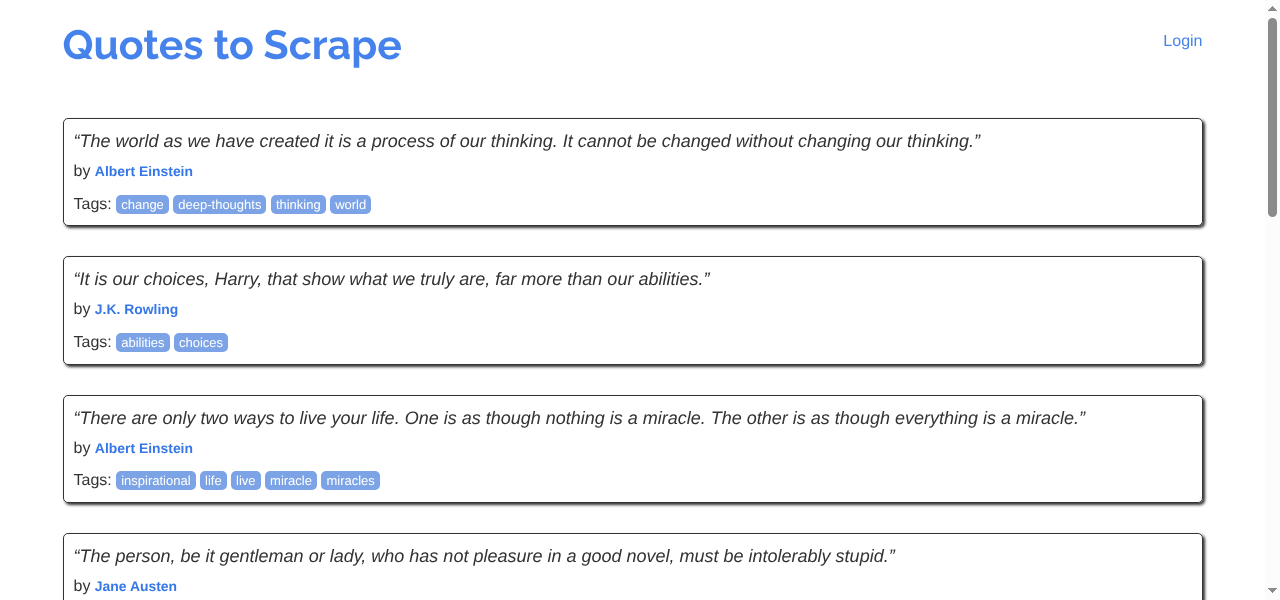

In [5]:
# Ask Selenium Manager for its paths: SeleniumManager().binary_paths(["--browser", "chrome"]); print whether each exists,
#   and whether the driver sits in ~/.cache/selenium
# Define make_options(): Options() with "--headless=new" if HEADLESS, and "--window-size=1280,800"
# Start driver = webdriver.Chrome(options=make_options()); print browserVersion and the chromedriver version
# Load https://quotes.toscrape.com/js/, print its title and how many div.quote elements it has, and save and show a screenshot
from IPython.display import Image, display
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By
from selenium.webdriver.common.selenium_manager import SeleniumManager

paths = SeleniumManager().binary_paths(["--browser", "chrome"])
for name in ["driver_path", "browser_path"]:
    print(name, "(found)" if Path(paths[name]).is_file() else "(MISSING)")
print("Driver chosen by Selenium Manager:", Path.home() / ".cache" / "selenium" in Path(paths["driver_path"]).parents)

def make_options():
    options = Options()
    if HEADLESS:
        options.add_argument("--headless=new")
    options.add_argument("--window-size=1280,800")
    # Empty on your laptop. The key runs as root on a server, where Chrome needs --no-sandbox ("Headless Mode")
    for flag in os.environ.get("LAB_CHROME_FLAGS", "").split():
        options.add_argument(flag)
    return options

driver = webdriver.Chrome(options=make_options())
print("Browser:", driver.capabilities["browserVersion"])
print("Driver: ", driver.capabilities["chrome"]["chromedriverVersion"].split()[0])

driver.get("https://quotes.toscrape.com/js/")
print(driver.title, len(driver.find_elements(By.CSS_SELECTOR, "div.quote")), "div.quote elements")
driver.save_screenshot("quotes-headless.png")
display(Image("quotes-headless.png", width=640))

<details>
<summary>💬 Discuss</summary>

- Headless Chrome names itself `HeadlessChrome` in its User-Agent, and every browser Selenium drives tells pages that `navigator.webdriver` is `true`. Week 5 called rewriting a User-Agent spoofing. Should a research scraper hide either one?
- The key adds `--no-sandbox` because it runs as root on a server. Why does the chapter tell you to leave the sandbox on, on your own laptop, even when Chrome won't start?
- What can the screenshot tell you that the count of quotes can't?

</details>

## Step 4 — Find elements, eight ways (9 minutes)

[`find_element()`](https://www.selenium.dev/documentation/webdriver/elements/finders/) takes a **locator**: a strategy from `By` and a value. On xkcd's front page, try five of the eight strategies the chapter tabulates: `By.CLASS_NAME` for the two navigation rows, `By.CSS_SELECTOR` for their links, `By.LINK_TEXT` and `By.PARTIAL_LINK_TEXT` for the **Random** and **< Prev** links, and `By.XPATH` to step up from the comic to its parent with `/..` ("The Eight Strategies").

`find_element()` returns the first match and raises `NoSuchElementException` when there's none; `find_elements()` returns a list, empty when there's none. To search inside an element, call the method on the element, and start an XPath with a dot: without it, `//` searches the whole page ("One Element or Many").

In [6]:
# Load https://xkcd.com. Count the elements with class "comicNav", and the links in them (CSS "ul.comicNav a"); print the first five links' text
# Print the Random link's href (By.LINK_TEXT) and the "Prev" link's text (By.PARTIAL_LINK_TEXT)
# With By.XPATH, step up from div#comic to its parent and print the parent's id
# Inside the first comicNav, count links with ".//a" and with "//a"
driver.get("https://xkcd.com")
print(len(driver.find_elements(By.CLASS_NAME, "comicNav")), "comicNav rows")
links = driver.find_elements(By.CSS_SELECTOR, "ul.comicNav a")
print(len(links), [a.text for a in links[:5]])

print(driver.find_element(By.LINK_TEXT, "Random").get_attribute("href"))
print(driver.find_element(By.PARTIAL_LINK_TEXT, "Prev").text)
print(driver.find_element(By.XPATH, "//div[@id='comic']/..").get_attribute("id"))

nav = driver.find_element(By.CLASS_NAME, "comicNav")
print(len(nav.find_elements(By.XPATH, ".//a")), "links in this row;",
      len(nav.find_elements(By.XPATH, "//a")), "links on the whole page")

2 comicNav rows
10 ['|<', '< Prev', 'Random', 'Next >', '>|']
https://c.xkcd.com/random/comic/
< Prev
middleContainer
5 links in this row; 47 links on the whole page


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** find the comic's image three different ways: `By.ID` for the comic's `<div>` and then `By.TAG_NAME` inside it, one `By.CSS_SELECTOR`, and one short `By.XPATH` that starts from the id. Check with `==` that all three found the same element, and print its `alt`.
**Share:** your three locators, whether `==` said `True`, and which one you'd trust after a redesign.

In [7]:
# Microsprint: find the comic's <img> with By.ID then By.TAG_NAME, with By.CSS_SELECTOR, and with By.XPATH
# Compare the three with ==, and print the image's alt attribute
by_id = driver.find_element(By.ID, "comic").find_element(By.TAG_NAME, "img")
by_css = driver.find_element(By.CSS_SELECTOR, "#comic img")
by_xpath = driver.find_element(By.XPATH, "//div[@id='comic']//img")
print(by_id == by_css == by_xpath, by_css.get_attribute("alt"))

True Vulnerability


<details>
<summary>💬 Discuss</summary>

- `By.ID` reached the browser as the CSS selector `[id="comic"]`. Why can Selenium rewrite three strategies as CSS, and what does that say about which strategy to learn first?
- Searching the first row with `//a` instead of `.//a` found every link on the page. What would a scraper with that bug have collected, and would it have raised an error?
- In week 5, the Inspector's **Copy XPath** described an element in one click. Which of your three locators would survive xkcd adding a banner above the comic, and which would a counted-down path like `/html/body/div[2]/div[2]/img` not?

</details>

## Step 5 — What Selenium reads, and what BeautifulSoup reads (5 minutes)

Selenium's `find_elements()` and BeautifulSoup's `find_all()` look alike, but they search different things. Selenium asks the browser about the page as it is now; BeautifulSoup searches a copy of HTML in your own Python. Two differences trip people up ("How This Differs from BeautifulSoup's `find_all()`").

**Text.** xkcd keeps a transcript of many comics in a `<div id="transcript">` that its style hides. Selenium's `.text` returns only what the browser displays; `get_attribute("textContent")` and BeautifulSoup's `get_text()` return what the markup holds. **Speed.** Each Selenium call is a request to chromedriver. Read the ten quotes on `/js/` both ways, and time each.

In [8]:
# Load https://xkcd.com/353/; print repr() of the transcript's .text, then the first 59 characters of its textContent
#   and of BeautifulSoup(driver.page_source).find("div", id="transcript").get_text()
# Load /js/ and time reading the ten quotes' text two ways: one .text per element (find_elements on "quote", then "text"),
#   and one BeautifulSoup parse of page_source
driver.get("https://xkcd.com/353/")  # The comic "Python"
transcript = driver.find_element(By.ID, "transcript")
print(repr(transcript.text))
print(transcript.get_attribute("textContent")[:59])
soup = BeautifulSoup(driver.page_source, "html.parser")
print(soup.find("div", id="transcript").get_text()[:59])

driver.get("https://quotes.toscrape.com/js/")
start = time.time()
texts = [q.find_element(By.CLASS_NAME, "text").text for q in driver.find_elements(By.CLASS_NAME, "quote")]
selenium_seconds = time.time() - start
start = time.time()
soup = BeautifulSoup(driver.page_source, "html.parser")
texts_bs = [span.get_text() for span in soup.select("div.quote span.text")]
soup_seconds = time.time() - start
print(f"Selenium: {len(texts)} texts in {selenium_seconds:.3f} s; BeautifulSoup: {len(texts_bs)} in {soup_seconds:.3f} s;",
      "same texts:", texts == texts_bs)

''
[[ Guy 1 is talking to Guy 2, who is floating in the sky ]]
[[ Guy 1 is talking to Guy 2, who is floating in the sky ]]


Selenium: 10 texts in 0.145 s; BeautifulSoup: 10 in 0.014 s; same texts: True


<details>
<summary>💬 Discuss</summary>

- Selenium said the transcript is empty; BeautifulSoup found it. Which answer is right for a study of what readers see, and which for a study of what the page contains?
- In week 6, BeautifulSoup only ever saw the HTML a server sent. What changes when its HTML comes from `driver.page_source`, and what stays the same?
- If reading ten quotes one call at a time took this long, what would that cost on a thousand pages? Where should a scraper use Selenium's locators, and where BeautifulSoup?

</details>

## Step 6 — Click and type (8 minutes)

xkcd's hover joke lives in the comic image's `title` attribute; its `alt` holds the comic's name ("Extracting Data"). Read both with `get_attribute()`. Then act like a reader: find the **Random** link with an XPath that matches part of its text with `contains()`, `.click()` it, and read the new comic.

Typing works the same way: find Wikipedia's search box by its `name`, `search`, type into it with [`send_keys()`](https://www.selenium.dev/documentation/webdriver/actions_api/keyboard/), and press Enter with `Keys.RETURN`. An exact title takes you straight to the article; anything else lands on a results page ("Typing and Searching"). Wikipedia welcomes automated access; a search engine like Google forbids it in its Terms of Service.

In [9]:
# Load https://xkcd.com and print the comic image's alt and title attributes (XPath "//div[@id='comic']//img")
# Click the Random link (XPath with contains(text(),'Random')), sleep 1 second, and print the new comic's title attribute
# On https://www.wikipedia.org, find the search box By.NAME "search", type "Colorado Buffaloes", press Keys.RETURN,
#   sleep 2 seconds, and print the page's title and the text of #firstHeading
from selenium.webdriver.common.keys import Keys

driver.get("https://xkcd.com")
img = driver.find_element(By.XPATH, "//div[@id='comic']//img")
print(f"Name (alt): {img.get_attribute('alt')}")
print(f"Hover joke (title): {img.get_attribute('title')}")

driver.find_element(By.XPATH, "//ul[@class='comicNav']//a[contains(text(),'Random')]").click()
time.sleep(1)
img = driver.find_element(By.XPATH, "//div[@id='comic']//img")
print(f"Random comic, {driver.current_url}: {img.get_attribute('title')}")

driver.get("https://www.wikipedia.org")
search_box = driver.find_element(By.NAME, "search")
search_box.send_keys("Colorado Buffaloes")
search_box.send_keys(Keys.RETURN)
time.sleep(2)
print(driver.title, "|", driver.find_element(By.ID, "firstHeading").text)

Name (alt): Vulnerability
Hover joke (title): Other numbers are largely unaffected, but anyone using '4' for their certificate key is urged to upgrade to '5'.


Random comic, https://xkcd.com/2428/: The best part of crashing a Mars briefing is you can get in a full 11 minutes of questions before they can start to respond.


Colorado Buffaloes - Wikipedia | Colorado Buffaloes


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 1. Search Wikipedia for a topic of your own the same way, and report where you landed. If it's a results page, count the results on it (`li.mw-search-result`) and print the first one's title.
**Share:** your query, whether you landed on an article or a results page, and the heading or the first result.

In [10]:
# Microsprint: search Wikipedia for your own query; print driver.title and driver.current_url
# If "Special:Search" is in the URL, count li.mw-search-result and print the first result's link text; otherwise print #firstHeading
driver.get("https://www.wikipedia.org")
search_box = driver.find_element(By.NAME, "search")
search_box.send_keys("headless browser scraping", Keys.RETURN)
time.sleep(2)
print(driver.title, "|", driver.current_url)
if "Special:Search" in driver.current_url:
    results = driver.find_elements(By.CSS_SELECTOR, "li.mw-search-result")
    print(len(results), "results; the first is", results[0].find_element(By.TAG_NAME, "a").text)
else:
    print(driver.find_element(By.ID, "firstHeading").text)

headless browser scraping - Search results - Wikipedia | https://en.wikipedia.org/wiki/Special:Search?search=headless+browser+scraping&go=Go&ns0=1
8 results; the first is Headless browser


<details>
<summary>💬 Discuss</summary>

- How did your code know whether it had landed on an article or a results page? What would it have done with the wrong one?
- Week 2 read `robots.txt` and Terms of Service as rules for scrapers. Do they still apply when a real browser does the requesting and a script does the clicking?
- `time.sleep(1)` after the click is a guess. What happens if the next comic takes three seconds to load?

</details>

## Step 7 — Wait for what you need (8 minutes)

`time.sleep()` guesses how long a page needs. An **explicit wait** asks instead: [`WebDriverWait`](https://www.selenium.dev/documentation/webdriver/waits/) checks a condition every half second, returns as soon as it's true, and raises `TimeoutException` if it never is. Conditions come from `expected_conditions`, imported as `EC`: `presence_of_element_located`, `visibility_of_element_located`, `element_to_be_clickable`, and `text_to_be_present_in_element` ("Waiting for Dynamic Content").

The practice page `/js-delayed/` waits ten seconds before its JavaScript adds the quotes. Look after a two-second sleep, then wait properly, and time it.

In [11]:
# Load https://quotes.toscrape.com/js-delayed/, sleep 2 seconds, and count the elements with class "quote"
# Then WebDriverWait(driver, 15).until(EC.presence_of_element_located((By.CLASS_NAME, "quote")))
# Print how many seconds passed since the page was requested, and count the quotes again
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.support.ui import WebDriverWait

start = time.time()
driver.get("https://quotes.toscrape.com/js-delayed/")
time.sleep(2)
print("After a 2-second sleep:", len(driver.find_elements(By.CLASS_NAME, "quote")), "quotes")

WebDriverWait(driver, 15).until(EC.presence_of_element_located((By.CLASS_NAME, "quote")))
print(f"After the wait, {time.time() - start:.1f} s in:", len(driver.find_elements(By.CLASS_NAME, "quote")), "quotes")

After a 2-second sleep: 0 quotes


After the wait, 10.3 s in: 10 quotes


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 4. For `https://quotes.toscrape.com/js/`, time three ways to load the page, three times each, with a one-second pause between: `requests.get()`; `driver.get()` plus a wait for the first quote, in the browser that's already open; and the same in a new browser that you start with `make_options()` and quit each time. Plot the median of each.
**Share:** the three medians, and which one surprised you.

method
browser already open        0.160
requests.get()              0.402
browser started and quit    1.526
Name: seconds, dtype: float64


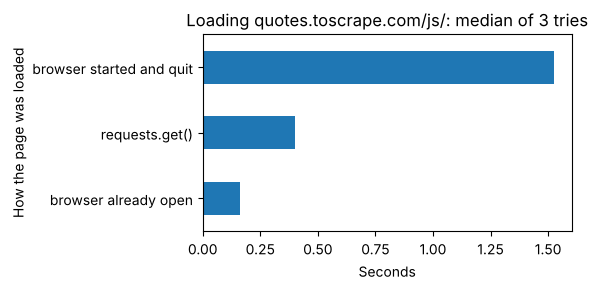

In [12]:
# Microsprint: on /js/, time requests.get(); driver.get() plus WebDriverWait for "quote" in the open browser;
#   and starting a new browser with make_options(), the same get and wait, then quit(). Three times each, pausing 1 s
# Plot each method's median as a bar chart with a title and axis labels
url = "https://quotes.toscrape.com/js/"

def load_in(browser):
    browser.get(url)
    WebDriverWait(browser, 10).until(EC.presence_of_element_located((By.CLASS_NAME, "quote")))

timings = []
for attempt in range(3):
    start = time.time()
    requests.get(url, headers=HEADERS, timeout=30)
    timings.append({"method": "requests.get()", "seconds": time.time() - start})
    time.sleep(1)

    start = time.time()
    load_in(driver)
    timings.append({"method": "browser already open", "seconds": time.time() - start})
    time.sleep(1)

    start = time.time()
    new_driver = webdriver.Chrome(options=make_options())
    load_in(new_driver)
    new_driver.quit()
    timings.append({"method": "browser started and quit", "seconds": time.time() - start})
    time.sleep(1)

medians = pd.DataFrame(timings).groupby("method")["seconds"].median().sort_values()
print(medians.round(3))

fig, ax = plt.subplots(figsize=(6, 3))
medians.plot.barh(ax=ax)
ax.set_title("Loading quotes.toscrape.com/js/: median of 3 tries")
ax.set_xlabel("Seconds")
ax.set_ylabel("How the page was loaded")
plt.tight_layout()
plt.show()

<details>
<summary>💬 Discuss</summary>

- A scraper that slept two seconds would have saved an empty page for every quote, with no error. Where else today could a fixed sleep have failed silently?
- An open browser can load a page faster than `requests.get()`: it keeps its connection open and caches the page's scripts, while each `requests.get()` starts over. So where does a browser's cost come from?
- View Source on `/js-delayed/`: the quotes are in a script there too. Did this page need a browser at all?

</details>

## Step 8 — Scroll to the end, then hand the page to BeautifulSoup (8 minutes)

On an infinite-scroll page, new content loads as you near the bottom. The chapter's `scrape_infinite_scroll()` scrolls with [`execute_script()`](https://www.selenium.dev/documentation/webdriver/interactions/), which runs JavaScript in the page, and compares `document.body.scrollHeight` before and after: when the page stops growing, there's nothing more ("Scraping Infinite Scroll Pages"). It returns the rendered HTML, and BeautifulSoup reads it all at once ("Passing to BeautifulSoup"): Selenium as the hands, BeautifulSoup as the eyes.

Copy the function as the chapter has it, run it on `/scroll`, and time it. When you have what you need, quit the browser: [`driver.quit()`](https://www.selenium.dev/documentation/webdriver/drivers/) closes every window and stops chromedriver.

In [13]:
# Copy the chapter's scrape_infinite_scroll(driver, max_scrolls=20, scroll_pause=2)
# Load https://quotes.toscrape.com/scroll, run it, and time it
# Parse the HTML it returns with BeautifulSoup into scroll_quotes, a DataFrame of author and text per div.quote; then driver.quit()
def scrape_infinite_scroll(driver, max_scrolls=20, scroll_pause=2):
    """Scroll an infinite-scroll page and collect all loaded content."""
    last_height = driver.execute_script("return document.body.scrollHeight")

    for i in range(max_scrolls):
        # Scroll to the bottom of the page
        driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")
        time.sleep(scroll_pause)

        # Check if the page grew
        new_height = driver.execute_script("return document.body.scrollHeight")
        if new_height == last_height:
            print(f"No new content after scroll {i+1}. Stopping.")
            break
        last_height = new_height
        print(f"Scroll {i+1}: page height grew to {new_height}px")

    # Return the fully-loaded page source
    return driver.page_source

driver.get("https://quotes.toscrape.com/scroll")
start = time.time()
html = scrape_infinite_scroll(driver)
scroll_seconds = time.time() - start

soup = BeautifulSoup(html, "html.parser")
scroll_quotes = pd.DataFrame([
    {"author": q.find("small", class_="author").get_text(), "text": q.find("span", class_="text").get_text()}
    for q in soup.find_all("div", class_="quote")
])
print(scroll_quotes.shape, f"in {scroll_seconds:.1f} seconds; the API loop took {api_seconds:.1f}")
driver.quit()

Scroll 1: page height grew to 3554px


Scroll 2: page height grew to 5118px


Scroll 3: page height grew to 6579px


Scroll 4: page height grew to 8066px


Scroll 5: page height grew to 9578px


Scroll 6: page height grew to 11245px


Scroll 7: page height grew to 12757px


Scroll 8: page height grew to 14424px


Scroll 9: page height grew to 15911px


No new content after scroll 10. Stopping.
(100, 2) in 20.1 seconds; the API loop took 13.5


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** check the scroll against Step 2. Do the scrolled page and the API give the same quotes? Compare the two sets of `text`, and the authors' counts.
**Share:** how many texts are in both, how many in only one, and whether the authors' counts agree.

In [14]:
# Microsprint: compare set(scroll_quotes["text"]) with set(api_quotes["text"]): how many in both, and in only one?
# Do value_counts() of author agree between the two DataFrames?
in_scroll, in_api = set(scroll_quotes["text"]), set(api_quotes["text"])
print(len(in_scroll & in_api), "texts in both;", len(in_scroll - in_api), "only scrolled;", len(in_api - in_scroll), "only from the API")
print("Authors' counts agree:", scroll_quotes["author"].value_counts().sort_index().equals(api_quotes["author"].value_counts().sort_index()))

100 texts in both; 0 only scrolled; 0 only from the API
Authors' counts agree: True


<details>
<summary>💬 Discuss</summary>

- The browser and the API collected the same quotes. Which route would you defend in a methods section, and why?
- In week 7, a page that fetches its content after it loads could archive as an empty shell. What would the Wayback Machine have kept of `/scroll`?
- `max_scrolls` caps the function at 20 scrolls. On a social feed with no end, how would you choose the cap, and what does week 2's idea of collecting only what you need say about it?

</details>

## Step 9 — The whole workflow, written defensively (5 minutes)

The chapter's `scrape_quotes()` puts it together on the `/js/` pages: start a headless browser, wait for the quotes, hand `page_source` to BeautifulSoup, check that each element exists before reading it, click **Next** if there is one, pause, and quit in a [`finally`](https://docs.python.org/3/tutorial/errors.html#defining-clean-up-actions) block, so that an error partway still closes the browser ("A Practical Selenium Workflow").

Copy it as the chapter has it, with one change: build the options with Step 3's `make_options()`, so that `HEADLESS` decides here too. Run it for three pages.

In [15]:
# Copy the chapter's scrape_quotes(max_pages=3), starting its browser with webdriver.Chrome(options=make_options())
# Run it for three pages, and print the DataFrame's shape and its first rows
def scrape_quotes(max_pages=3):
    """Scrape quotes from Quotes to Scrape's JavaScript pages, and only there.

    The steps of the workflow carry over to other sites:
    1. Launch a headless browser
    2. Navigate to the page
    3. Wait for JavaScript to render the content
    4. Extract data via BeautifulSoup
    5. Handle pagination
    6. Clean up
    The address, tags, and class names in quotation marks belong to this site.
    """
    options = make_options()  # The chapter writes Options() and --headless=new here
    driver = webdriver.Chrome(options=options)

    all_results = []

    try:
        driver.get("https://quotes.toscrape.com/js/")  # This site's address

        for page in range(max_pages):
            # Wait for the quotes to render (up to 10 seconds)
            WebDriverWait(driver, 10).until(
                EC.presence_of_element_located((By.CLASS_NAME, "quote"))  # This site's class
            )

            # Pass rendered HTML to BeautifulSoup
            soup = BeautifulSoup(driver.page_source, "html.parser")

            # Extract data from this page, with this site's tags and classes
            for item in soup.find_all("div", class_="quote"):
                # Check that both elements exist before calling .text — the same defensive pattern you learned for static scraping
                text_tag = item.find("span", class_="text")
                author_tag = item.find("small", class_="author")
                if text_tag is None or author_tag is None:
                    continue  # Skip malformed items rather than crash
                all_results.append({
                    "text": text_tag.text.strip(),
                    "author": author_tag.text.strip(),
                    "page": page + 1
                })

            # Click "Next" if there is one; the last page has none.
            # li.next a is this site's selector for its Next link
            next_links = driver.find_elements(By.CSS_SELECTOR, "li.next a")
            if not next_links:
                break  # No more pages
            next_links[0].click()
            time.sleep(1)  # Pause between pages

    finally:
        driver.quit()  # Always clean up

    return pd.DataFrame(all_results)

quotes_df = scrape_quotes(max_pages=3)
print(quotes_df.shape)
quotes_df.head()

(30, 3)


,text,author,page
0,“The world as we have created it is a process ...,Albert Einstein,1
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling,1
2,“There are only two ways to live your life. On...,Albert Einstein,1
3,"“The person, be it gentleman or lady, who has ...",Jane Austen,1
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe,1


<details>
<summary>💬 Discuss</summary>

- Which strings in `scrape_quotes()` belong to Quotes to Scrape, and which lines would carry over unchanged to another site?
- Without `try`/`finally`, what happens to the headless browser when the wait times out? How would you even notice?
- Week 6's Oscars parser worked only on oscars.org, and this one works only here. Is that a flaw in the parsers, or the nature of scraping?

</details>

## Step 10 — Behind a login (8 minutes)

Quotes to Scrape has a practice login that accepts any username and password. Logged in, each quote shows a **(Goodreads page)** link that logged-out visitors don't see, so counting those links tells you whether you're logged in ("Pages Behind a Login").

The chapter's first way is by hand: start a browser **with a window**, open the login page, and let `input("Log in in the Chrome window, then press Enter here")` hold the cell while you type, so that your password never enters your code. A headless browser has no window to type in, so here we use the chapter's second way, for code that must log in by itself: read the password from an environment variable, or ask for it with [`getpass()`](https://docs.python.org/3/library/getpass.html), which hides what you type and keeps it out of the notebook ("Passwords and Other Credentials"). On the practice site, type anything. Never print a password or a cookie's value; a cookie's *name* is safe.

In [16]:
# Read password from os.environ.get("QUOTES_PASSWORD") or getpass("Password: ") (any password works on the practice site)
# Start a browser with make_options(); count "(Goodreads page)" links (By.LINK_TEXT) on https://quotes.toscrape.com/ logged out
# Go to /login, type a username into #username and the password into #password with Keys.RETURN, then count the links again
# Print the names (not the values) of the browser's cookies, then quit
from getpass import getpass

password = os.environ.get("QUOTES_PASSWORD") or getpass("Password: ")

driver = webdriver.Chrome(options=make_options())
try:
    driver.get("https://quotes.toscrape.com/")
    print("Logged out:", len(driver.find_elements(By.LINK_TEXT, "(Goodreads page)")), "Goodreads links")

    driver.get("https://quotes.toscrape.com/login")
    driver.find_element(By.ID, "username").send_keys("your-username")
    driver.find_element(By.ID, "password").send_keys(password, Keys.RETURN)
    WebDriverWait(driver, 10).until(EC.presence_of_element_located((By.CLASS_NAME, "quote")))
    print("Logged in: ", len(driver.find_elements(By.LINK_TEXT, "(Goodreads page)")), "Goodreads links")
    print("Cookies:", [cookie["name"] for cookie in driver.get_cookies()])
finally:
    driver.quit()

Logged out: 0 Goodreads links


Logged in:  10 Goodreads links
Cookies: ['session']


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 6, on paper. Choose a site where you have an account and data you'd like to study. Without collecting anything, list the routes to it: an API and its price, a researcher program, data donation, asking the site, and a logged-in browser. For each, note who carries the risk: you, the platform, or the people in the data.
**Share:** your site, the route you'd take, and one risk that route puts on someone other than you.

In [17]:
# Microsprint: answer as comments. Your site, each route with its cost and who carries the risk, and the route you'd take
# Site: Reddit, to study how a city's subreddit talks about housing.
# API: week 3 quoted $0.24 per 1,000 calls for apps above the free limits; the risk is mostly the terms, on me.
# Researcher program: check whether Reddit runs one and what it requires; slow, but the platform shares the risk.
# Data donation: volunteers export their own data; consent is clean, but only the volunteers' posts, a biased sample.
# Asking: a message to the moderators and to Reddit; free, and may be ignored.
# Logged-in browser: free, but breaks terms I agreed to, stakes my account, and the posters never agreed to a dataset.
# I'd take the API, scoped to one subreddit and a fixed window, and tell an IRB the posts are public but the people didn't consent.

<details>
<summary>💬 Discuss</summary>

- Technically, logging in changed one cookie. What else changed: for you, for the site, and for the people whose posts you'd see?
- Week 3 put X's enterprise API at $42,000 a month and up. Is a logged-in browser the cheaper route, and who pays the difference?
- The chapter keeps a session in a Chrome profile folder so the next run can skip the login. Why does it say to treat that folder like your password, and where should it live?

</details>

## Step 11 — The same with a Playwright script (5 minutes)

[Playwright](https://playwright.dev/python/) drives a browser too, with three differences: it installs its own browsers, its **locators** wait on their own when you act on or read an element, and it can record a script while you click (`python -m playwright codegen`). Its simple *sync* API won't run inside a notebook, because Jupyter already runs an event loop of its own ("Why Not in the Notebook?"). So write a script file, with `%%writefile` as the first line of the cell, and run it as a separate program with the notebook's own Python, as you would from a terminal.

The script is the chapter's first one, plus its "Catching the JSON Behind a Page": scroll `/scroll` and catch the API reply that the scrolling triggers, the request we watched by hand in Step 2. Playwright starts headless unless you pass `headless=False`. It needs its browsers first (`python -m playwright install chromium`, about 320 MB); in an older environment, add the library with `%conda install -y -c conda-forge playwright-python`.

In [18]:
%%writefile xkcd_alt.py
# A Playwright script: launch Chromium (headless; pass headless=False to watch), open xkcd, print the comic's alt and title
# Then open /scroll, and with page.expect_response() catch the "/api/quotes?page=2" reply while page.mouse.wheel(0, 20000) scrolls
# Print that reply's page number and how many quotes it held
from playwright.sync_api import sync_playwright

with sync_playwright() as p:
    browser = p.chromium.launch()  # Headless by default; pass headless=False to watch it work
    page = browser.new_page()
    page.goto("https://xkcd.com")

    img = page.locator("#comic img")
    print(img.get_attribute("alt"))    # The comic's name
    print(img.get_attribute("title"))  # The hover joke

    page.goto("https://quotes.toscrape.com/scroll")
    with page.expect_response(lambda r: "/api/quotes?page=2" in r.url) as info:
        page.mouse.wheel(0, 20000)
    data = info.value.json()
    print(data["page"], len(data["quotes"]))

    browser.close()

Writing xkcd_alt.py


In [19]:
# Run the script with this notebook's Python, as a separate program: !{sys.executable} xkcd_alt.py
!{sys.executable} xkcd_alt.py

Vulnerability
Other numbers are largely unaffected, but anyone using '4' for their certificate key is urged to upgrade to '5'.


2 10


<details>
<summary>💬 Discuss</summary>

- Playwright's locator waited for the comic without a `WebDriverWait`. Which of today's Selenium lines did the script not need?
- An AI agent connected through Playwright MCP could have collected these quotes for you. If it had, what could your methods section cite, compared with a script it wrote for you to read and rerun?
- Selenium drives Chrome, Firefox, Edge, or Safari as you have them installed; Playwright brings its own copies, pinned to its version. Which would you rather explain in a replication package, and why?

</details>

## Step 12 — What did we learn? (4 minutes)

In a few sentences, as comments or in a Markdown cell:

- Of the three checks in Steps 1 and 2, which found the quotes without a browser, and on which pages? How many requests and seconds did the API take, against the scroll's in Step 8?
- In Step 7's microsprint, what did the browser cost per page once it was open, and what did it cost to start? For which page today was a browser the only way in?
- In Step 10, what told you that you were logged in, and what did logging in cost besides the code?
- Which lines of `scrape_quotes()` would you keep for a site of your own, and which would you have to find again in developer tools?

**Recommended Exercises ahead** (in the chapter's companion notebook, due Sunday):

- Step 1, fetch your page statically and count your element: Step 1's `requests` and BeautifulSoup check, and week 2's `robots.txt`.
- Step 2, start a headless browser: Step 3's `make_options()` and the `HEADLESS` switch from Step 0.
- Step 3, wait, then measure again: Step 7's `WebDriverWait`, and Step 5's `page_source` handed to BeautifulSoup.
- Step 4, load more: Step 8's `scrape_infinite_scroll()`, or Step 6's `.click()` for a **Load More** button.
- Step 5, tabulate and clean up: Step 2's DataFrame from a list of dictionaries, and Step 9's `driver.quit()` in `finally`.
- Step 6, interpret: Steps 1 and 2's checks, and Step 7's timings.

In [20]:
# Your answers here, as comments
# Steps 1-2: requests found 0 div.quote elements on /js/, but its script held all 10 quotes; the hidden API gave all
#   100 quotes in 10 requests and 13.5 s. Step 8's browser scrolled to the same 100 (every text matched) in 20.1 s.
# Step 7: once open, the browser loaded /js/ in 0.16 s, faster than requests.get()'s 0.40 s, because it reuses its
#   connection and cache; starting a browser and quitting it took 1.53 s. No page today strictly needed a browser:
#   each held its quotes in a script or behind a JSON API. The login came closest.
# Step 10: 0 Goodreads links logged out, 10 logged in, and one cookie, "session". Besides the code, logging in costs
#   the terms you agreed to, your account, and the privacy of the people whose posts you'd see.
# Keep scrape_quotes()'s shape: start, wait, page_source to BeautifulSoup, None checks, Next by find_elements, pause,
#   quit in finally. Find again in developer tools: the address, "quote", the span and small classes, and "li.next a".

## Friday: from the lab to the textbook (15 minutes)

What did the lab turn up that chapter 8 could do better? Some places to look:

- **Outputs that changed.** xkcd's front page and the random comic change; did the chapter's xkcd numbers (2 navigation rows, 10 links, 47 links on the page) still hold when you ran Step 4? Did Step 3's browser version match the chapter's?
- **A cell that broke**, on your laptop and not on the instructor's screen: Selenium Manager, a missing driver, a window that wouldn't open. The chapter's "When Selenium Manager Fails" and "Common Issues to Debug" are where a fix would go.
- **A sentence that confused you.** The chapter's examples run on whatever page the browser happens to be on: which page is it on when "Scrolling" presses Page Down, or when "Passing to BeautifulSoup" counts links?
- **A microsprint that would make a good exercise**, such as checking the API's `top_ten_tags` against a loop, or the three locators for one element.

See [`handouts/common/revision-framework.md`](../../handouts/common/revision-framework.md) for how to propose a revision.